In [1]:
from scripts.metrics import Stratified_plan_level_MAE
from scripts.metrics import dim_ceil
from scripts.metrics import IDDCurveLoss
from scripts.metrics import BeamMaskedMAELoss

In [1]:
from monai.transforms import Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityRanged, Spacingd, ResizeWithPadOrCropd
from scripts.data_loader import ExtractSlabsAroundZ, InjectGaussianBeamPriord
from scripts.metaembedder import InjectEnergyDepositionFieldd
from omegaconf import OmegaConf

In [2]:
from omegaconf import OmegaConf

cfg = OmegaConf.load("configs/default_config.yaml")

In [1]:
cfg = cfg['komondor']
cfg['batch_size'] = 1

NameError: name 'cfg' is not defined

In [30]:
from scripts.data_loader import ExtractSlabsAroundZ
import json

train_json = json.load(open('data/train.json'))
sample_dict = train_json[-10]

In [2]:
from monai.transforms import Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityRanged, Spacingd, ResizeWithPadOrCropd, EnsureTyped


In [32]:
train_transforms = Compose([
    LoadImaged(keys=["ct", "gt_dose"], image_only=False),
    EnsureChannelFirstd(keys=["ct", "gt_dose"]),
    ScaleIntensityRanged(keys=['ct'], a_min=cfg['ct_min'], a_max=cfg['ct_max'], b_min=0.0, b_max=1.0, clip=True),
    ExtractSlabsAroundZ(keys=["ct", "gt_dose"], source_key="ray_source", slice_radius=15),
    Spacingd(keys=["ct", "gt_dose"], pixdim=cfg['pixdim'], mode='trilinear'),
    ResizeWithPadOrCropd(keys=["ct", "gt_dose"], spatial_size=cfg['roi_size']),
    EnsureTyped(keys=['ct', "gt_dose", "ray_source", "ray_target", "condition"])
])

data = train_transforms(sample_dict)

## GT dose spread analysis

We are analyzing the ground-truth dose distribution because that is the supervised target. The injected energy field is only an auxiliary prior and is not the quantity we want to explain here.

This analysis does:
1. Load the GT dose volume from the sample.
2. Find the peak dose location in `gt_dose`.
3. Extract the axial profile around that peak.
4. Estimate the lateral/axial spread in millimeters.
5. Visualize the central GT dose slice and the profile.


gt_dose shape: (128, 128, 32)
gt_dose peak value: 0.00079154497
gt_dose peak location index: (67, 88, 15)
axial mean z index: 14.930846868116973
axial sigma [mm]: 7.6452954960556045
approx axial FWHM [mm]: 15.0


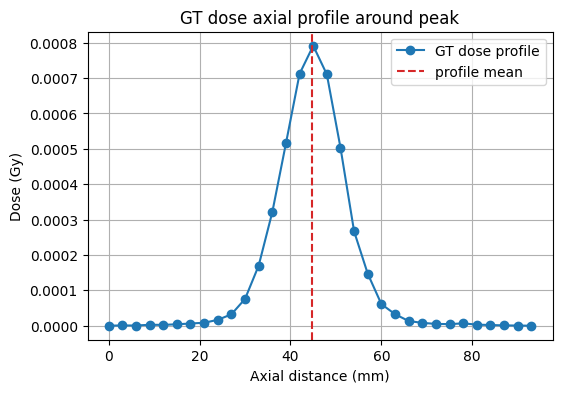

(-0.5, 127.5, 127.5, -0.5)

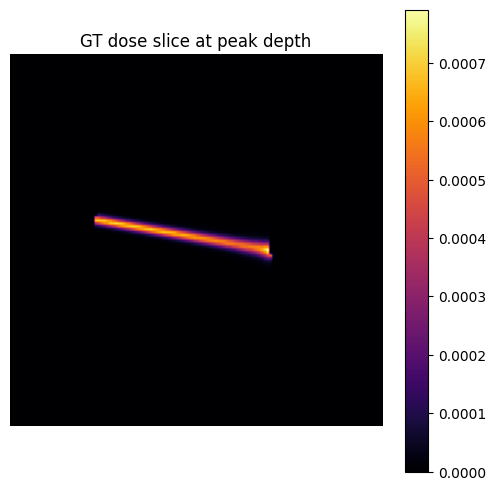

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# GT dose is the supervised target; the prior is only an auxiliary input.
gt_dose = data['gt_dose'].squeeze().cpu().numpy()

if gt_dose.ndim != 3:
    raise ValueError(f'Expected 3D gt_dose, got shape {gt_dose.shape}')

peak_idx = np.unravel_index(np.argmax(gt_dose), gt_dose.shape)
profile = gt_dose[peak_idx[0], peak_idx[1], :]

z = np.arange(profile.shape[-1])
mean_z = np.sum(z * profile) / np.sum(profile)
sigma_z = np.sqrt(np.sum((z - mean_z) ** 2 * profile) / np.sum(profile))
fwhm_z = np.sum(profile > 0.5 * profile.max()) * cfg['pixdim'][-1]

print('gt_dose shape:', gt_dose.shape)
print('gt_dose peak value:', gt_dose.max())
print('gt_dose peak location index:', peak_idx)
print('axial mean z index:', mean_z)
print('axial sigma [mm]:', sigma_z * cfg['pixdim'][-1])
print('approx axial FWHM [mm]:', fwhm_z)

plt.figure(figsize=(6, 4))
plt.plot(z * cfg['pixdim'][-1], profile, marker='o', label='GT dose profile')
plt.axvline(mean_z * cfg['pixdim'][-1], color='C3', linestyle='--', label='profile mean')
plt.xlabel('Axial distance (mm)')
plt.ylabel('Dose (Gy)')
plt.title('GT dose axial profile around peak')
plt.grid(True)
plt.legend()
plt.show()

central_xy_slice = gt_dose[:, :, peak_idx[2]]
plt.figure(figsize=(6, 6))
plt.imshow(central_xy_slice, cmap='inferno')
plt.title('GT dose slice at peak depth')
plt.colorbar()
plt.axis('off')


## Compare multiple samples

Compute the energy spread for a small set of samples to see which ones are broader or tighter.

Computing GT dose spread:   0%|                                                                                                                                                                    | 0/20 [00:00<?, ?it/s]

Computing GT dose spread: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:27<00:00,  1.39s/it]


Broadest GT dose samples:
{'beam_length_mm': 1000.0, 'sigma_mm': 8.95397747631484, 'fwhm_mm': 21.08661695672145, 'peak_idx': (51, 34, 14), 'gt_max': 0.0009222003864124417}
{'beam_length_mm': 1000.0, 'sigma_mm': 8.852501294406782, 'fwhm_mm': 20.84764054832797, 'peak_idx': (52, 35, 14), 'gt_max': 0.0008929630275815725}
{'beam_length_mm': 1000.0, 'sigma_mm': 8.440534267246276, 'fwhm_mm': 19.87745819936498, 'peak_idx': (51, 36, 15), 'gt_max': 0.000995979062281549}
{'beam_length_mm': 1000.0, 'sigma_mm': 7.967701936676072, 'fwhm_mm': 18.76393806087215, 'peak_idx': (52, 41, 15), 'gt_max': 0.001013237633742392}
{'beam_length_mm': 1000.0, 'sigma_mm': 7.700216131602861, 'fwhm_mm': 18.134008989924737, 'peak_idx': (52, 45, 15), 'gt_max': 0.0011127535253763199}

Narrowest GT dose samples:
{'beam_length_mm': 1000.0, 'sigma_mm': 6.546561579717997, 'fwhm_mm': 15.417152520235883, 'peak_idx': (52, 53, 14), 'gt_max': 0.0014339991612359881}
{'beam_length_mm': 1000.0, 'sigma_mm': 6.4506078116641, 'fwhm_mm'

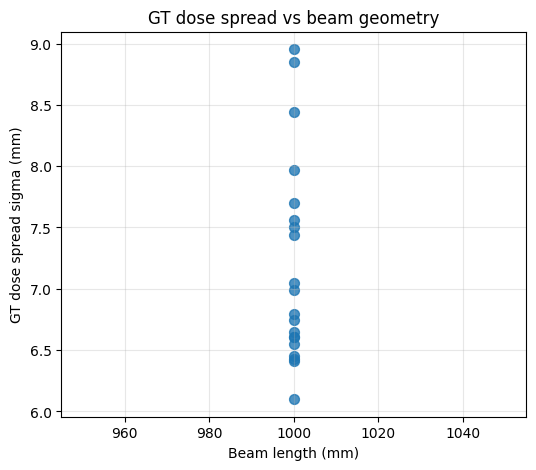

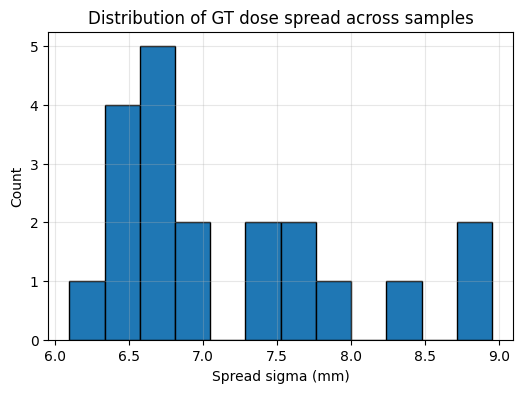

In [10]:
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt


def compute_gt_dose_spread(sample_dict, cfg):
    """Measure spread of the ground-truth dose field, not the injected prior."""
    d = train_transforms(sample_dict)
    gt = d['gt_dose'].squeeze().cpu().numpy()
    if gt.ndim != 3:
        raise ValueError(f'Expected 3D gt_dose, got shape {gt.shape}')

    peak_idx = np.unravel_index(np.argmax(gt), gt.shape)
    profile = gt[peak_idx[0], peak_idx[1], :]
    profile = profile / (profile.max() + 1e-8)

    z = np.arange(profile.shape[0]) * cfg['pixdim'][-1]
    center = np.sum(z * profile) / np.sum(profile)
    sigma_mm = np.sqrt(np.sum((z - center) ** 2 * profile) / np.sum(profile))
    fwhm_mm = 2.355 * sigma_mm

    source = np.asarray(d['ray_source'], dtype=np.float32)
    target = np.asarray(d['ray_target'], dtype=np.float32)
    beam_length_mm = np.linalg.norm(target - source)

    return {
        'beam_length_mm': float(beam_length_mm),
        'sigma_mm': float(sigma_mm),
        'fwhm_mm': float(fwhm_mm),
        'peak_idx': peak_idx,
        'gt_max': float(gt.max()),
    }


sample_list = train_json[:20]
spread_stats = []
for s in tqdm(sample_list, desc='Computing GT dose spread'):
    try:
        spread_stats.append(compute_gt_dose_spread(s, cfg))
    except Exception as e:
        print('Skipped sample due to error:', e)

spread_stats = sorted(spread_stats, key=lambda x: x['sigma_mm'], reverse=True)
print('Broadest GT dose samples:')
for row in spread_stats[:5]:
    print(row)
print('\nNarrowest GT dose samples:')
for row in spread_stats[-5:]:
    print(row)

beam_lengths = [x['beam_length_mm'] for x in spread_stats]
sigmas = [x['sigma_mm'] for x in spread_stats]

plt.figure(figsize=(6, 5))
plt.scatter(beam_lengths, sigmas, s=50, c='C0', alpha=0.8)
plt.xlabel('Beam length (mm)')
plt.ylabel('GT dose spread sigma (mm)')
plt.title('GT dose spread vs beam geometry')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(sigmas, bins=12, edgecolor='black')
plt.xlabel('Spread sigma (mm)')
plt.ylabel('Count')
plt.title('Distribution of GT dose spread across samples')
plt.grid(True, alpha=0.3)
plt.show()


In [3]:
import matplotlib.pyplot as plt

ct_img = data["ct"].cpu().numpy()
if ct_img.ndim == 4 and ct_img.shape[0] == 1:
    ct_img = ct_img[0]

slice_idx = ct_img.shape[-1] // 2
plt.figure(figsize=(6, 6))
plt.imshow(ct_img[..., slice_idx], cmap="gray")
plt.axis("off")

NameError: name 'data' is not defined

### Beam profile in general direction case (by Aron)

In [34]:
import numpy as np
import torch
import matplotlib.pyplot as plt


def get_beam_basis(sample, flip_lps_to_ras=True):
    source = np.asarray(
        sample["ray_source"],
        dtype=np.float64,
    ).copy()

    target = np.asarray(
        sample["ray_target"],
        dtype=np.float64,
    ).copy()

    if flip_lps_to_ras:
        source[0] *= -1
        source[1] *= -1

        target[0] *= -1
        target[1] *= -1

    beam_dir = target - source

    beam_dir /= (
        np.linalg.norm(beam_dir)
        + 1e-12
    )

    # Olyan referencia-tengelyt választunk,
    # ami a legkevésbé párhuzamos a beammel.
    ref = np.zeros(3)
    ref[
        np.argmin(np.abs(beam_dir))
    ] = 1.0

    u_axis = np.cross(
        beam_dir,
        ref,
    )

    u_axis /= (
        np.linalg.norm(u_axis)
        + 1e-12
    )

    v_axis = np.cross(
        beam_dir,
        u_axis,
    )

    v_axis /= (
        np.linalg.norm(v_axis)
        + 1e-12
    )

    return beam_dir, u_axis, v_axis

In [35]:
def extract_transverse_profile(
    sample,
    plane_thickness_mm=None,
    bin_size_mm=1.0,
    dose_threshold_rel=1e-4,
    flip_lps_to_ras=True,
):
    dose_meta = sample["gt_dose"]

    dose = (
        dose_meta[0]
        .detach()
        .cpu()
        .numpy()
    )

    affine = (
        dose_meta.affine
        .detach()
        .cpu()
        .numpy()
    )

    # ----------------------------------------
    # Beam basis
    # ----------------------------------------

    beam_dir, u_axis, v_axis = (
        get_beam_basis(
            sample,
            flip_lps_to_ras=
                flip_lps_to_ras,
        )
    )

    # ----------------------------------------
    # Globális dose maximum
    # ----------------------------------------

    peak_idx = np.array(
        np.unravel_index(
            np.argmax(dose),
            dose.shape,
        ),
        dtype=np.float64,
    )

    peak_h = np.append(
        peak_idx,
        1.0,
    )

    peak_world = (
        affine @ peak_h
    )[:3]

    # ----------------------------------------
    # Voxel spacing
    # ----------------------------------------

    spacing = np.array([
        np.linalg.norm(
            affine[:3, 0]
        ),
        np.linalg.norm(
            affine[:3, 1]
        ),
        np.linalg.norm(
            affine[:3, 2]
        ),
    ])

    if plane_thickness_mm is None:
        plane_thickness_mm = (
            spacing.max()
        )

    # ----------------------------------------
    # Csak releváns dose voxelek
    # ----------------------------------------

    dose_max = dose.max()

    mask = (
        dose
        >= dose_threshold_rel
        * dose_max
    )

    indices = np.argwhere(
        mask
    )

    values = dose[
        mask
    ].astype(np.float64)

    # ----------------------------------------
    # voxel -> world
    # ----------------------------------------

    homogeneous = np.column_stack([
        indices.astype(np.float64),
        np.ones(len(indices)),
    ])

    world = (
        homogeneous @ affine.T
    )[:, :3]

    # ----------------------------------------
    # A peakhez viszonyított pozíció
    # ----------------------------------------

    r = world - peak_world

    # Beam irányú eltérés a peak síkjától
    longitudinal = (
        r @ beam_dir
    )

    # Csak a beamre merőleges vékony slab
    plane_mask = (
        np.abs(longitudinal)
        <= plane_thickness_mm / 2.0
    )

    r = r[plane_mask]
    values = values[plane_mask]

    if len(values) < 5:
        return None

    # ----------------------------------------
    # Transverse coordinates
    # ----------------------------------------

    u = r @ u_axis
    v = r @ v_axis

    # ----------------------------------------
    # Dose-weighted centroid
    # ----------------------------------------

    total = values.sum()

    mean_u = (
        np.sum(values * u)
        / total
    )

    mean_v = (
        np.sum(values * v)
        / total
    )

    du = u - mean_u
    dv = v - mean_v

    # ----------------------------------------
    # 2D covariance
    # ----------------------------------------

    var_u = (
        np.sum(
            values * du**2
        )
        / total
    )

    var_v = (
        np.sum(
            values * dv**2
        )
        / total
    )

    cov_uv = (
        np.sum(
            values * du * dv
        )
        / total
    )

    covariance = np.array([
        [var_u, cov_uv],
        [cov_uv, var_v],
    ])

    eigvals, eigvecs = (
        np.linalg.eigh(
            covariance
        )
    )

    order = np.argsort(
        eigvals
    )[::-1]

    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    eigvals = np.maximum(
        eigvals,
        0,
    )

    sigma_major = np.sqrt(
        eigvals[0]
    )

    sigma_minor = np.sqrt(
        eigvals[1]
    )

    # ----------------------------------------
    # Principal coordinates
    # ----------------------------------------

    transverse_points = (
        np.column_stack([
            du,
            dv,
        ])
    )

    principal = (
        transverse_points
        @ eigvecs
    )

    major_coord = principal[:, 0]
    minor_coord = principal[:, 1]

    # ----------------------------------------
    # 1D integrated profiles
    # ----------------------------------------

    major_edges = np.arange(
        major_coord.min() - bin_size_mm,
        major_coord.max()
        + 2 * bin_size_mm,
        bin_size_mm,
    )

    minor_edges = np.arange(
        minor_coord.min() - bin_size_mm,
        minor_coord.max()
        + 2 * bin_size_mm,
        bin_size_mm,
    )

    major_profile, _ = (
        np.histogram(
            major_coord,
            bins=major_edges,
            weights=values,
        )
    )

    minor_profile, _ = (
        np.histogram(
            minor_coord,
            bins=minor_edges,
            weights=values,
        )
    )

    major_x = (
        major_edges[:-1]
        + major_edges[1:]
    ) / 2

    minor_x = (
        minor_edges[:-1]
        + minor_edges[1:]
    ) / 2

    # ----------------------------------------
    # 2D transverse dose map
    # ----------------------------------------

    margin = 2 * bin_size_mm

    u_edges = np.arange(
        u.min() - margin,
        u.max() + margin,
        bin_size_mm,
    )

    v_edges = np.arange(
        v.min() - margin,
        v.max() + margin,
        bin_size_mm,
    )

    dose_2d, _, _ = np.histogram2d(
        u,
        v,
        bins=[
            u_edges,
            v_edges,
        ],
        weights=values,
    )

    return {
        "peak_idx": peak_idx,
        "peak_world": peak_world,

        "beam_dir": beam_dir,
        "u_axis": u_axis,
        "v_axis": v_axis,

        "u": u,
        "v": v,
        "dose_values": values,

        "sigma_major_mm":
            float(sigma_major),

        "sigma_minor_mm":
            float(sigma_minor),

        "fwhm_major_mm":
            float(2.355 * sigma_major),

        "fwhm_minor_mm":
            float(2.355 * sigma_minor),

        "ellipticity":
            float(
                sigma_major
                / (
                    sigma_minor
                    + 1e-12
                )
            ),

        "major_x": major_x,
        "major_profile":
            major_profile,

        "minor_x": minor_x,
        "minor_profile":
            minor_profile,

        "dose_2d": dose_2d,
        "u_edges": u_edges,
        "v_edges": v_edges,

        "plane_thickness_mm":
            plane_thickness_mm,
    }

In [39]:
sample = data

result = extract_transverse_profile(
    sample,
    plane_thickness_mm=3.0,
    bin_size_mm=1.0,
)

print(
    "sigma major:",
    result["sigma_major_mm"],
    "mm",
)

print(
    "sigma minor:",
    result["sigma_minor_mm"],
    "mm",
)

print(
    "FWHM major:",
    result["fwhm_major_mm"],
    "mm",
)

print(
    "FWHM minor:",
    result["fwhm_minor_mm"],
    "mm",
)

print(
    "ellipticity:",
    result["ellipticity"],
)

sigma major: 8.641860055961947 mm
sigma minor: 7.2173709175716825 mm
FWHM major: 20.351580431790385 mm
FWHM minor: 16.996908510881312 mm
ellipticity: 1.1973695345102677


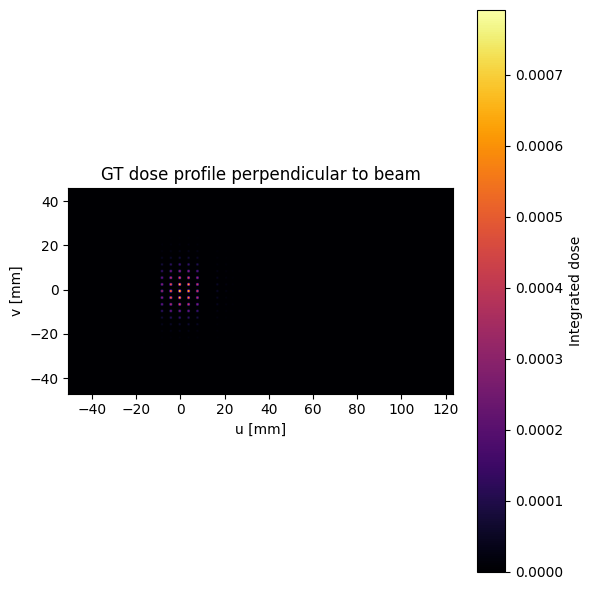

In [40]:
plt.figure(figsize=(6, 6))

plt.imshow(
    result["dose_2d"].T,
    origin="lower",
    extent=[
        result["u_edges"][0],
        result["u_edges"][-1],
        result["v_edges"][0],
        result["v_edges"][-1],
    ],
    aspect="equal",
    cmap="inferno",
)

plt.xlabel("u [mm]")
plt.ylabel("v [mm]")

plt.title(
    "GT dose profile perpendicular to beam"
)

plt.colorbar(
    label="Integrated dose"
)

plt.tight_layout()
plt.show()

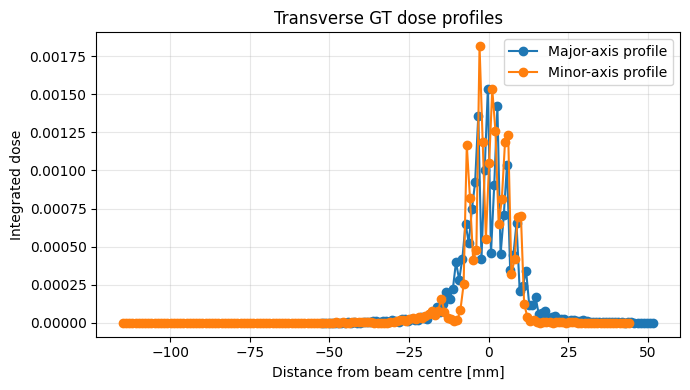

In [41]:
plt.figure(figsize=(7, 4))

plt.plot(
    result["major_x"],
    result["major_profile"],
    marker="o",
    label="Major-axis profile",
)

plt.plot(
    result["minor_x"],
    result["minor_profile"],
    marker="o",
    label="Minor-axis profile",
)

plt.xlabel(
    "Distance from beam centre [mm]"
)

plt.ylabel(
    "Integrated dose"
)

plt.title(
    "Transverse GT dose profiles"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
from monai.transforms import LoadImaged
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn
from monai.transforms import LoadImaged, Compose
import json
from omegaconf import OmegaConf

from monai.visualize import matshow3d

In [5]:
from pathlib import Path

flare_root = Path("/home/nr_domh/nr_dose/flare_data")
# For FLARE Better, use:
# flare_root = Path("/home/nr_domh/nr_dose/flare_better/output")

files = sorted(path for path in flare_root.rglob("*") if path.is_file())

print(f"Found {len(files)} files under {flare_root}")
for path in files[:10]:
    print(path)

Found 1851 files under /home/nr_domh/nr_dose/flare_data
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_0.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_10.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_100.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_110.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_120.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_130.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_140.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_150.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_160.nii.gz
/home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_170.nii.gz


In [6]:
from pathlib import Path

data_path = Path("/home/nr_domh/nr_dose/flare_data")
sample = data_path / "metadata_FLARE22_Tr_0001_0000.json"

print("Sample:", sample)
print("Exists:", sample.exists())

Sample: /home/nr_domh/nr_dose/flare_data/metadata_FLARE22_Tr_0001_0000.json
Exists: True


In [7]:
from pathlib import Path

flare_root = Path("/home/nr_domh/nr_dose") / "flare_data"
for p in flare_root.rglob("*"):
    if p.suffix.lower() in [".nii", ".nii.gz", ".mha", ".mhd", ".nrrd"]:
        print(p)

In [8]:
from pathlib import Path
from monai.transforms import Compose, LoadImaged

# FLARE dose files are NIfTI files stored directly in flare_data.
# For FLARE Better, change this to Path("/home/nr_domh/nr_dose/flare_better/output").
data_path = Path("/home/nr_domh/nr_dose/flare_data")
sample_id = "FLARE22_Tr_0001_0000"

dose_path = data_path / f"dose_{sample_id}_angle_0.nii.gz"
if not dose_path.exists():
    matches = sorted(data_path.glob(f"dose_{sample_id}_angle_*.nii.gz"))
    if not matches:
        raise FileNotFoundError(f"No dose NIfTI found for {sample_id} under {data_path}")
    dose_path = matches[0]

transforms = Compose([
    LoadImaged(keys=["dose"], image_only=False),
])
loaded = transforms({"dose": str(dose_path)})
img = loaded["dose"]
metadata = loaded.get("dose_meta_dict", getattr(img, "meta", {}))

print("Loaded:", dose_path)
print("Image shape:", tuple(img.shape))
print("Metadata:", metadata)

Loaded: /home/nr_domh/nr_dose/flare_data/dose_FLARE22_Tr_0001_0000_angle_0.nii.gz
Image shape: (512, 512, 110)
Metadata: {'sizeof_hdr': array(348, dtype=int32), 'extents': array(0, dtype=int32), 'session_error': array(0, dtype=int16), 'dim_info': array(0, dtype=uint8), 'dim': array([  3, 512, 512, 110,   1,   1,   1,   1], dtype=int16), 'intent_p1': array(0., dtype=float32), 'intent_p2': array(0., dtype=float32), 'intent_p3': array(0., dtype=float32), 'intent_code': array(0, dtype=int16), 'datatype': array(64, dtype=int16), 'bitpix': array(64, dtype=int16), 'slice_start': array(0, dtype=int16), 'pixdim': array([1.      , 0.644531, 0.644531, 2.5     , 0.      , 0.      ,
       0.      , 0.      ], dtype=float32), 'vox_offset': array(0., dtype=float32), 'scl_slope': array(nan, dtype=float32), 'scl_inter': array(nan, dtype=float32), 'slice_end': array(0, dtype=int16), 'slice_code': array(0, dtype=uint8), 'xyzt_units': array(10, dtype=uint8), 'cal_max': array(0., dtype=float32), 'cal_min'

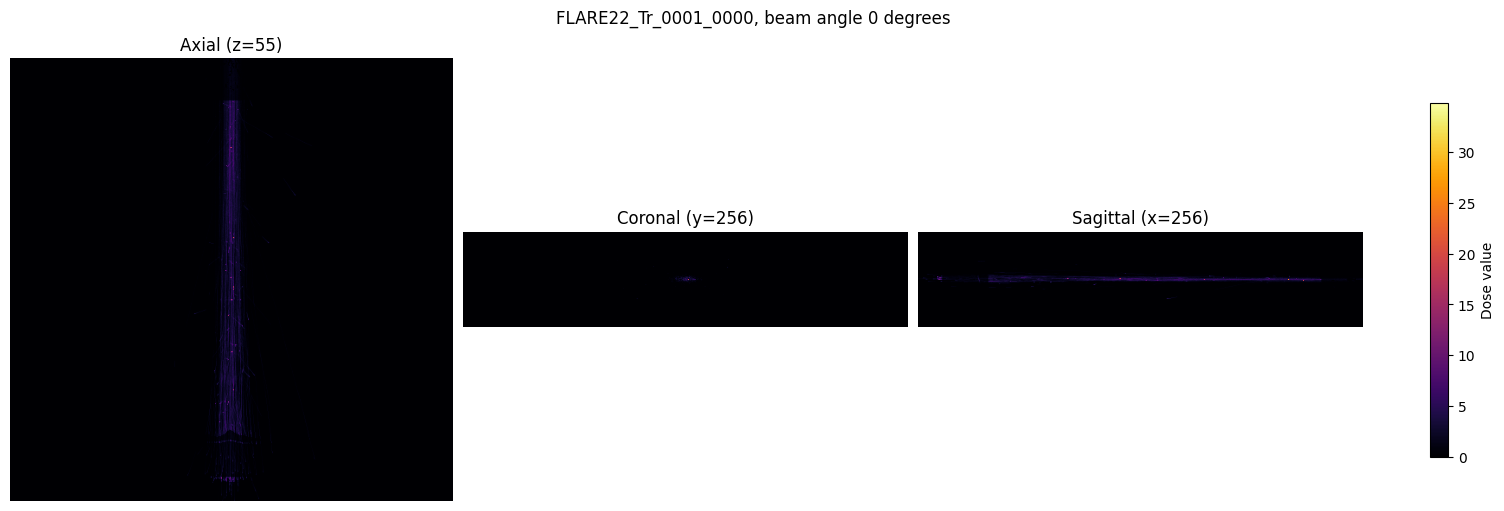

In [9]:
import matplotlib.pyplot as plt
import numpy as np

volume = img.detach().cpu().numpy()
mid_x, mid_y, mid_z = (size // 2 for size in volume.shape)
vmax = float(volume.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
slices = [
    (volume[:, :, mid_z], f"Axial (z={mid_z})"),
    (volume[:, mid_y, :], f"Coronal (y={mid_y})"),
    (volume[mid_x, :, :], f"Sagittal (x={mid_x})"),
]

for axis, (slice_image, title) in zip(axes, slices):
    image = axis.imshow(slice_image.T, cmap="inferno", origin="lower", vmin=0, vmax=vmax)
    axis.set_title(title)
    axis.set_axis_off()

fig.colorbar(image, ax=axes, label="Dose value", shrink=0.8)
fig.suptitle(f"{sample_id}, beam angle 0 degrees")
plt.show()

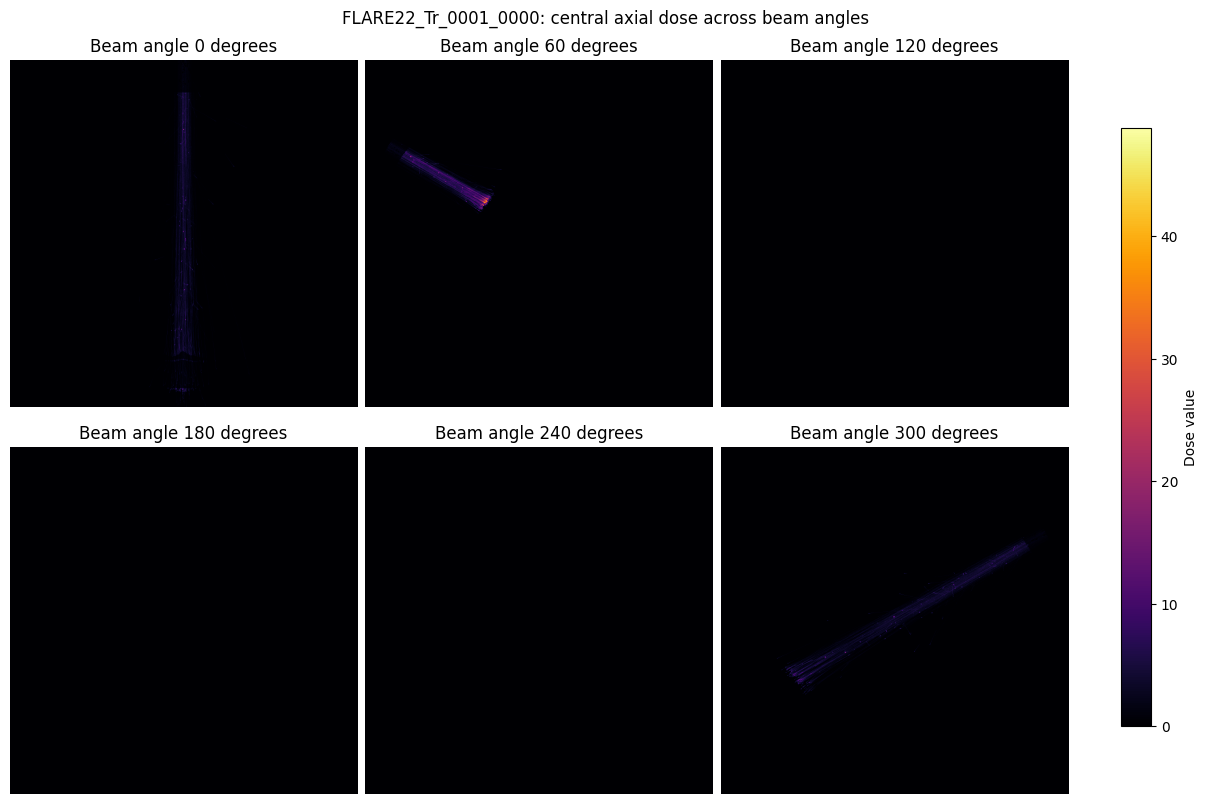

In [10]:
angles = [0, 60, 120, 180, 240, 300]
load_dose = LoadImaged(keys=["dose"], image_only=True)
angle_slices = []
shared_max = 0.0
slice_index = None
expected_shape = None

for angle in angles:
    angle_path = data_path / f"dose_{sample_id}_angle_{angle}.nii.gz"
    if not angle_path.exists():
        print(f"Skipping missing file: {angle_path.name}")
        continue

    angle_img = load_dose({"dose": str(angle_path)})["dose"]
    angle_volume = angle_img.detach().cpu().numpy()
    if angle_volume.ndim != 3:
        raise ValueError(f"Expected a 3D dose volume, got {angle_volume.shape}")
    if expected_shape is None:
        expected_shape = angle_volume.shape
        slice_index = expected_shape[2] // 2
    elif angle_volume.shape != expected_shape:
        raise ValueError(f"Shape mismatch for {angle_path.name}: {angle_volume.shape}")

    angle_slices.append((angle, angle_volume[:, :, slice_index].copy()))
    shared_max = max(shared_max, float(angle_volume.max()))
    del angle_img, angle_volume

if not angle_slices:
    raise FileNotFoundError(f"No selected angle files found for {sample_id} in {data_path}")

fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for axis, (angle, slice_image) in zip(axes.flat, angle_slices):
    image = axis.imshow(
        slice_image.T,
        cmap="inferno",
        origin="lower",
        vmin=0,
        vmax=shared_max,
    )
    axis.set_title(f"Beam angle {angle} degrees")
    axis.set_axis_off()

for axis in axes.flat[len(angle_slices):]:
    axis.set_axis_off()

fig.colorbar(image, ax=axes, label="Dose value", shrink=0.8)
fig.suptitle(f"{sample_id}: central axial dose across beam angles")
plt.show()

Verified 0 deg -> dose_FLARE22_Tr_0001_0000_angle_0.nii.gz; beam source (mm): [-0.0, 500.0, 0.0]; center-slice max: 33.2908
Verified 60 deg -> dose_FLARE22_Tr_0001_0000_angle_60.nii.gz; beam source (mm): [-433.0127018922193, 250.00000000000006, 0.0]; center-slice max: 48.8254
Verified 120 deg -> dose_FLARE22_Tr_0001_0000_angle_120.nii.gz; beam source (mm): [-433.01270189221935, -249.9999999999999, 0.0]; center-slice max: 3.68867e-06
Verified 180 deg -> dose_FLARE22_Tr_0001_0000_angle_180.nii.gz; beam source (mm): [-6.123233995736766e-14, -500.0, 0.0]; center-slice max: 9.15628e-06
Verified 240 deg -> dose_FLARE22_Tr_0001_0000_angle_240.nii.gz; beam source (mm): [433.0127018922192, -250.00000000000023, 0.0]; center-slice max: 4.99366e-06
Verified 300 deg -> dose_FLARE22_Tr_0001_0000_angle_300.nii.gz; beam source (mm): [433.0127018922193, 250.00000000000006, 0.0]; center-slice max: 35.168


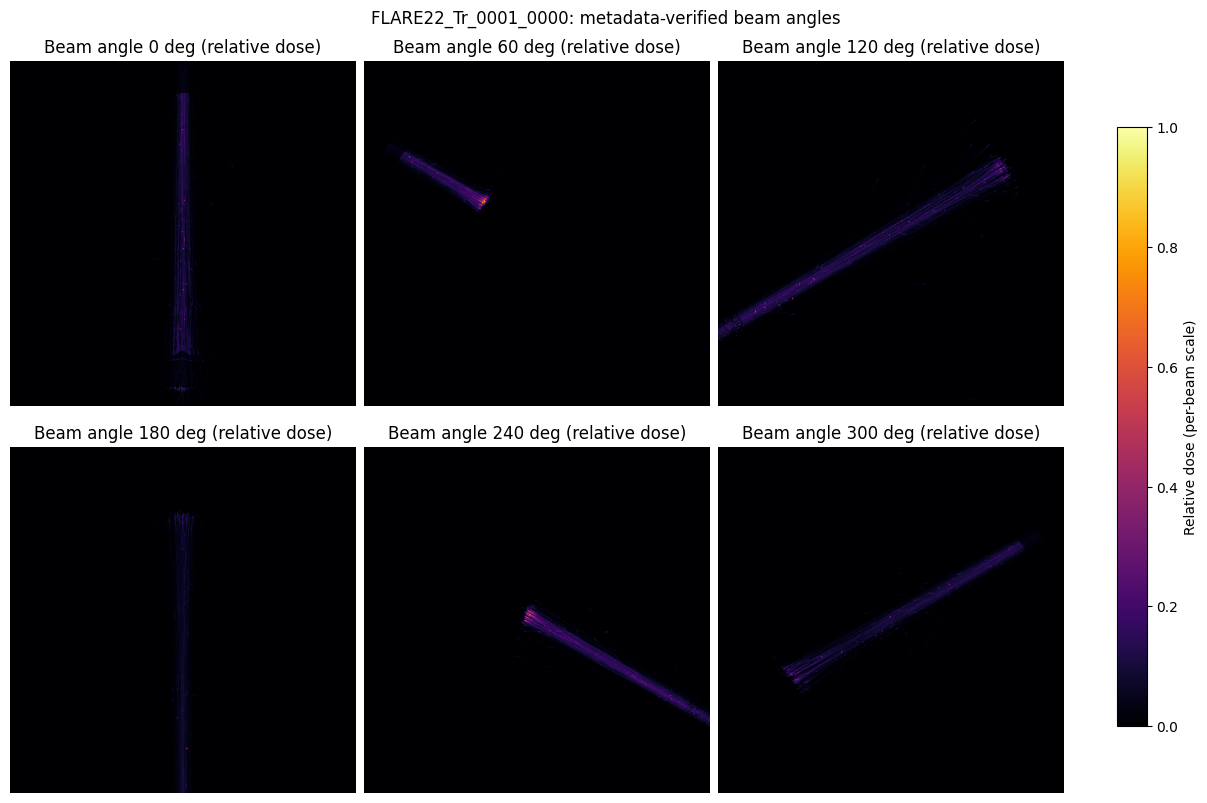

In [11]:
import json
import matplotlib.pyplot as plt
import numpy as np

metadata_path = data_path / f"metadata_{sample_id}.json"
with metadata_path.open() as metadata_file:
    flare_metadata = json.load(metadata_file)
rays_by_filename = {
    ray["output_filename"]: ray
    for ray in flare_metadata["rays"]
}

verified_slices = []
for angle, slice_image in angle_slices:
    filename = f"dose_{sample_id}_angle_{angle}.nii.gz"
    ray = rays_by_filename.get(filename)
    if ray is None:
        raise ValueError(f"{filename} is not listed in {metadata_path.name}")

    metadata_angle = int(ray["angle"])
    if metadata_angle != angle:
        raise ValueError(
            f"Angle mismatch for {filename}: plot says {angle}, metadata says {metadata_angle}"
        )

    slice_max = float(slice_image.max())
    print(
        f"Verified {metadata_angle} deg -> {filename}; "
        f"beam source (mm): {ray['beam_source_mm']}; "
        f"center-slice max: {slice_max:.6g}"
    )
    relative_slice = slice_image / slice_max if slice_max > 0 else np.zeros_like(slice_image)
    verified_slices.append((metadata_angle, relative_slice))

fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for axis, (angle, slice_image) in zip(axes.flat, verified_slices):
    image = axis.imshow(
        slice_image.T,
        cmap="inferno",
        origin="lower",
        vmin=0,
        vmax=1,
    )
    axis.set_title(f"Beam angle {angle} deg (relative dose)")
    axis.set_axis_off()

for axis in axes.flat[len(verified_slices):]:
    axis.set_axis_off()

fig.colorbar(image, ax=axes, label="Relative dose (per-beam scale)", shrink=0.8)
fig.suptitle(f"{sample_id}: metadata-verified beam angles")
plt.show()

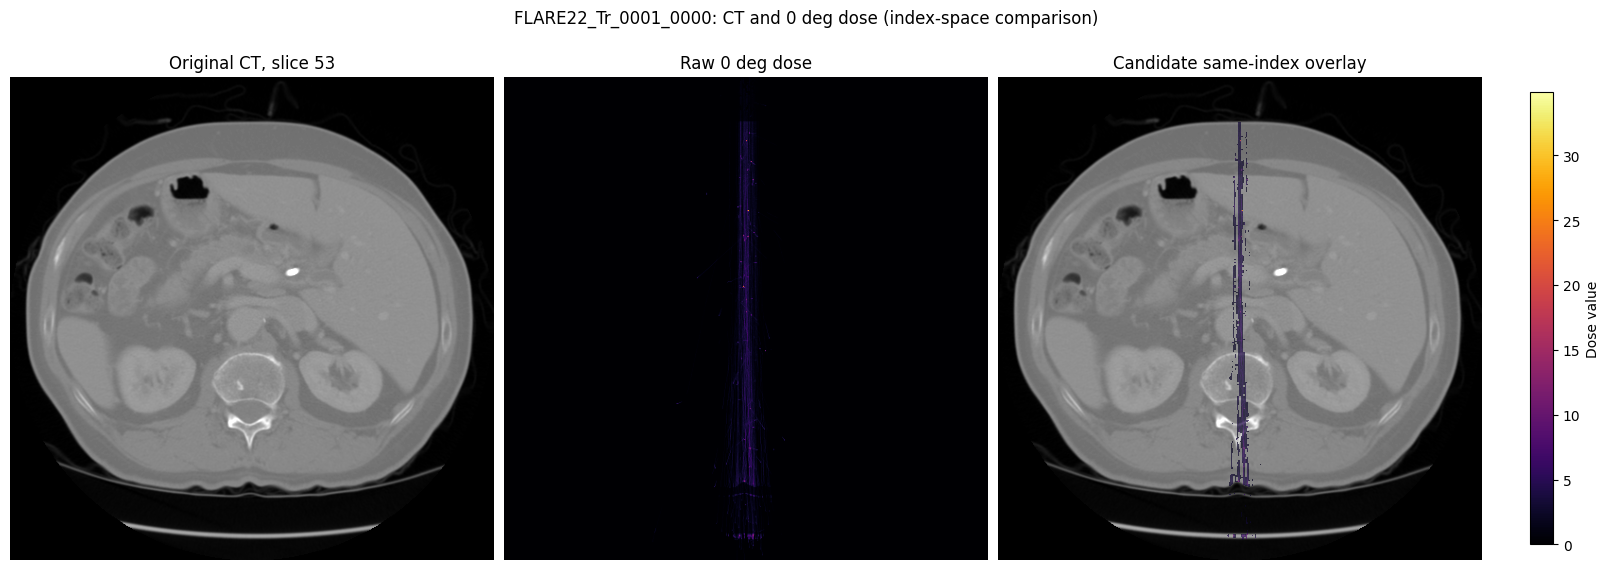

CT shape: (512, 512, 110)
Dose shape: (512, 512, 110)
CT spacing (mm): [0.644531 0.644531 2.5     ]
Dose spacing (mm): [0.64453101 0.64453101 2.5       ]
CT affine matches dose affine: False


In [11]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

ct_path = Path("/home/nr_domh/nr_dose/flair_origin/images") / f"{sample_id}.nii.gz"
if not ct_path.exists():
    raise FileNotFoundError(f"CT file not found: {ct_path}")

ct_nii = nib.load(str(ct_path))
ct_volume = ct_nii.get_fdata(dtype=np.float32)
dose_volume = img.detach().cpu().numpy()
dose_affine = img.affine.detach().cpu().numpy()
ct_spacing = np.asarray(ct_nii.header.get_zooms()[:3])
dose_spacing = np.linalg.norm(dose_affine[:3, :3], axis=0)

if tuple(ct_nii.shape) != tuple(dose_volume.shape):
    raise ValueError(f"CT shape {ct_nii.shape} differs from dose shape {dose_volume.shape}")
if not np.allclose(ct_spacing, dose_spacing, atol=1e-4):
    raise ValueError(f"CT spacing {ct_spacing} differs from dose spacing {dose_spacing}")

# Use one shared voxel index; do not resample using the inconsistent CT affine.
slice_index = int(np.argmax(dose_volume.max(axis=(0, 1))))
ct_slice = ct_volume[:, :, slice_index].T
dose_slice = dose_volume[:, :, slice_index].T
slice_dose_max = float(dose_slice.max())
visible_dose = np.ma.masked_less(dose_slice, slice_dose_max * 0.05)

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)
axes[0].imshow(ct_slice, cmap="gray", origin="lower", vmin=-1000, vmax=1000)
axes[0].set_title(f"Original CT, slice {slice_index}")
axes[0].set_axis_off()

image = axes[1].imshow(
    dose_slice,
    cmap="inferno",
    origin="lower",
    vmin=0,
    vmax=slice_dose_max,
)
axes[1].set_title("Raw 0 deg dose")
axes[1].set_axis_off()

axes[2].imshow(ct_slice, cmap="gray", origin="lower", vmin=-1000, vmax=1000)
axes[2].imshow(
    visible_dose,
    cmap="inferno",
    origin="lower",
    alpha=0.7,
    vmin=0,
    vmax=slice_dose_max,
)
axes[2].set_title("Candidate same-index overlay")
axes[2].set_axis_off()
fig.colorbar(image, ax=axes[1:], label="Dose value", shrink=0.8)
fig.suptitle(f"{sample_id}: CT and 0 deg dose (index-space comparison)")
plt.show()

print("CT shape:", tuple(ct_nii.shape))
print("Dose shape:", tuple(dose_volume.shape))
print("CT spacing (mm):", ct_spacing)
print("Dose spacing (mm):", dose_spacing)
print("CT affine matches dose affine:", np.allclose(ct_nii.affine, dose_affine, atol=1e-4))
print("WARNING: same-index display only; physical alignment is not validated.")

In [6]:
def volume_world_bounds(shape, affine):
    voxel_corners = np.array([
        [i, j, k]
        for i in (0, shape[0] - 1)
        for j in (0, shape[1] - 1)
        for k in (0, shape[2] - 1)
    ])
    world_corners = nib.affines.apply_affine(affine, voxel_corners)
    return world_corners.min(axis=0), world_corners.max(axis=0)

ct_min_world, ct_max_world = volume_world_bounds(ct_nii.shape, ct_nii.affine)
dose_min_world, dose_max_world = volume_world_bounds(dose_volume.shape, dose_affine)
print("CT affine:\n", ct_nii.affine)
print("Dose affine:\n", dose_affine)
print("CT world bounds (mm):", ct_min_world, "to", ct_max_world)
print("Dose world bounds (mm):", dose_min_world, "to", dose_max_world)

CT affine:
 [[   0.64453101    0.            0.         -329.35534668]
 [   0.            0.64453101    0.         -329.35534668]
 [   0.            0.            2.5           0.        ]
 [   0.            0.            0.            1.        ]]
Dose affine:
 [[  -0.64453101    0.            0.          164.67767334]
 [   0.           -0.64453101    0.          164.67767334]
 [   0.            0.            2.5        -136.25      ]
 [   0.            0.            0.            1.        ]]
CT world bounds (mm): [-329.35534668 -329.35534668    0.        ] to [2.38418579e-07 2.38418579e-07 2.72500000e+02]
Dose world bounds (mm): [-164.67767358 -164.67767358 -136.25      ] to [164.67767334 164.67767334 136.25      ]


In [9]:
from pathlib import Path
import nibabel as nib
import numpy as np

sample_dose_filename = f"dose_{sample_id}_angle_0.nii.gz"
dose_header_paths = {
    "flare_data": Path("/home/nr_domh/nr_dose/flare_data") / sample_dose_filename,
    "flare_better": Path("/home/nr_domh/nr_dose/flare_better/output") / sample_dose_filename,
}

print("Original CT affine:\n", ct_nii.affine)
for dataset_name, header_path in dose_header_paths.items():
    if not header_path.exists():
        print(f"{dataset_name}: file not found: {header_path}")
        continue
    header_image = nib.load(str(header_path))
    print(f"{dataset_name} shape:", header_image.shape)
    print(f"{dataset_name} affine:\n", header_image.affine)
    print(
        f"{dataset_name} affine matches CT:",
        tuple(header_image.shape) == tuple(ct_nii.shape)
        and np.allclose(header_image.affine, ct_nii.affine, atol=1e-4),
    )

Original CT affine:
 [[   0.64453101    0.            0.         -329.35534668]
 [   0.            0.64453101    0.         -329.35534668]
 [   0.            0.            2.5           0.        ]
 [   0.            0.            0.            1.        ]]
flare_data shape: (512, 512, 110)
flare_data affine:
 [[  -0.64453101    0.            0.          164.67767334]
 [   0.           -0.64453101    0.          164.67767334]
 [   0.            0.            2.5        -136.25      ]
 [   0.            0.            0.            1.        ]]
flare_data affine matches CT: False
flare_better shape: (512, 512, 110)
flare_better affine:
 [[  -0.64453101    0.            0.          164.67767334]
 [   0.           -0.64453101    0.          164.67767334]
 [   0.            0.            2.5        -136.25      ]
 [   0.            0.            0.            1.        ]]
flare_better affine matches CT: False


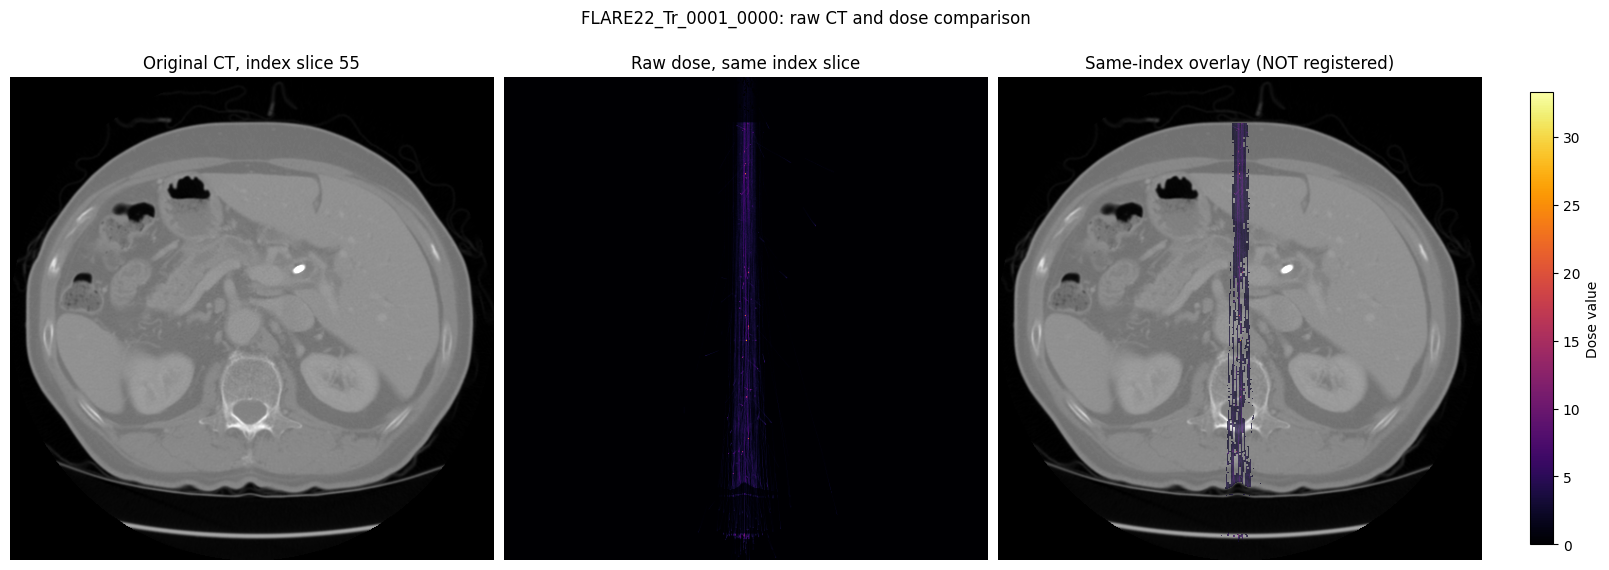

CT affine equals dose affine: False
This overlay compares voxel indices only; physical alignment is not established.


In [8]:
import matplotlib.pyplot as plt
import numpy as np

if tuple(ct_only_volume.shape) != tuple(dose_volume.shape):
    raise ValueError(
        f"Raw array shapes differ: CT {ct_only_volume.shape}, dose {dose_volume.shape}"
    )

comparison_slice = ct_only_volume.shape[2] // 2
ct_index_slice = ct_only_volume[:, :, comparison_slice].T
dose_index_slice = dose_volume[:, :, comparison_slice].T
slice_dose_max = float(dose_index_slice.max())
if slice_dose_max <= 0:
    raise ValueError(f"Dose slice {comparison_slice} contains no positive dose")
visible_index_dose = np.ma.masked_less(dose_index_slice, slice_dose_max * 0.05)

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)
axes[0].imshow(
    ct_index_slice,
    cmap="gray",
    origin="lower",
    vmin=-1000,
    vmax=1000,
)
axes[0].set_title(f"Original CT, index slice {comparison_slice}")
axes[0].set_axis_off()

image = axes[1].imshow(
    dose_index_slice,
    cmap="inferno",
    origin="lower",
    vmin=0,
    vmax=slice_dose_max,
)
axes[1].set_title("Raw dose, same index slice")
axes[1].set_axis_off()

axes[2].imshow(
    ct_index_slice,
    cmap="gray",
    origin="lower",
    vmin=-1000,
    vmax=1000,
)
axes[2].imshow(
    visible_index_dose,
    cmap="inferno",
    origin="lower",
    alpha=0.7,
    vmin=0,
    vmax=slice_dose_max,
)
axes[2].set_title("Same-index overlay (NOT registered)")
axes[2].set_axis_off()

fig.colorbar(image, ax=axes[1:], label="Dose value", shrink=0.8)
fig.suptitle(f"{sample_id}: raw CT and dose comparison")
plt.show()
print("CT affine equals dose affine:", ct_grid_matches)
print("This overlay compares voxel indices only; physical alignment is not established.")

In [10]:
ct_body_mask = ct_only_volume > -500
active_dose_mask = dose_volume > float(dose_volume.max()) * 0.05
peak_index = np.unravel_index(np.argmax(dose_volume), dose_volume.shape)
active_indices = np.argwhere(active_dose_mask)
body_indices = np.argwhere(ct_body_mask)

print("Dose peak voxel index:", peak_index)
print("CT value at dose peak (HU):", float(ct_only_volume[peak_index]))
print("Fraction of >5% dose voxels inside CT body mask:", float(ct_body_mask[active_dose_mask].mean()))
print("Dose-active voxel index bounds:", active_indices.min(axis=0), "to", active_indices.max(axis=0))
print("CT body voxel index bounds:", body_indices.min(axis=0), "to", body_indices.max(axis=0))

Dose peak voxel index: (258, 369, 53)
CT value at dose peak (HU): 126.0
Fraction of >5% dose voxels inside CT body mask: 0.9588020368825341
Dose-active voxel index bounds: [13  0  1] to [412 508 107]
CT body voxel index bounds: [ 2 22  0] to [510 469 109]


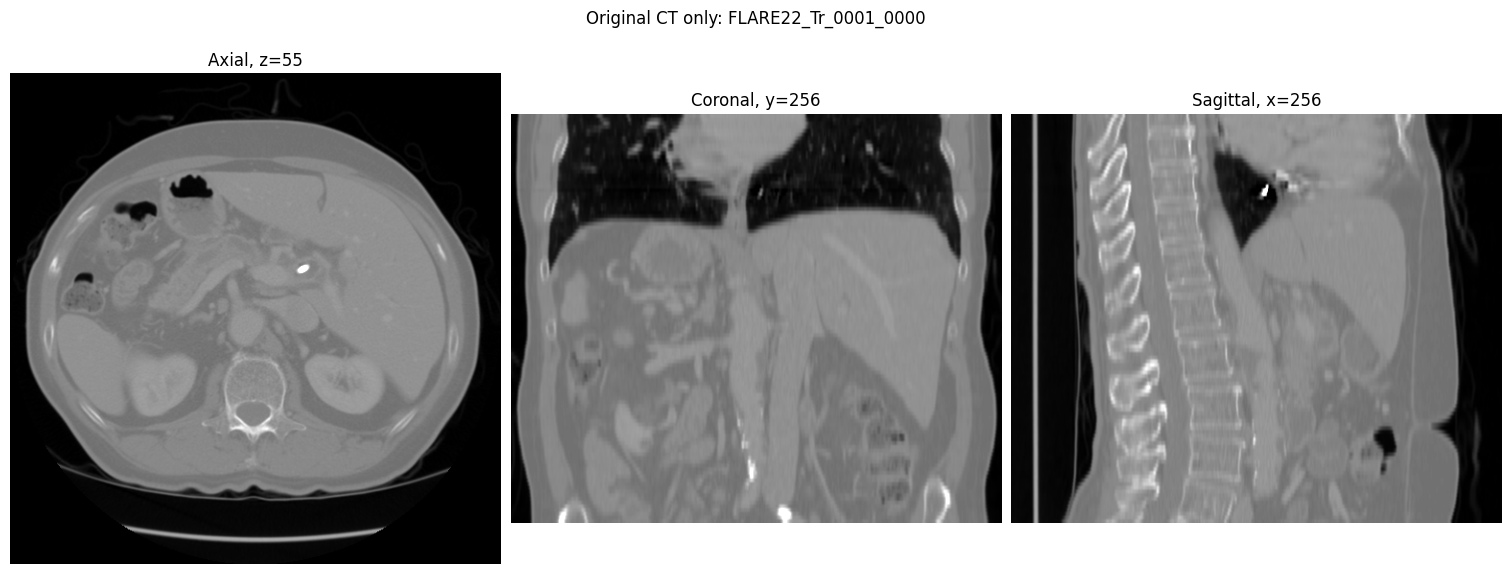

CT shape: (512, 512, 110)
Voxel spacing (mm): (0.644531, 0.644531, 2.5)
CT intensity range: -1024.0 to 3071.0


In [1]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

sample_id = "FLARE22_Tr_0001_0000"
ct_only_path = Path("/home/nr_domh/nr_dose/flair_origin/images") / f"{sample_id}.nii.gz"
if not ct_only_path.exists():
    raise FileNotFoundError(f"CT file not found: {ct_only_path}")

ct_only_nii = nib.load(str(ct_only_path))
ct_only_volume = ct_only_nii.get_fdata(dtype=np.float32)
spacing = ct_only_nii.header.get_zooms()[:3]
mid_x, mid_y, mid_z = (size // 2 for size in ct_only_volume.shape)

views = [
    (ct_only_volume[:, :, mid_z].T, f"Axial, z={mid_z}", spacing[1] / spacing[0]),
    (ct_only_volume[:, mid_y, :].T, f"Coronal, y={mid_y}", spacing[2] / spacing[0]),
    (ct_only_volume[mid_x, :, :].T, f"Sagittal, x={mid_x}", spacing[2] / spacing[1]),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 6), constrained_layout=True)
for axis, (slice_image, title, aspect) in zip(axes, views):
    axis.imshow(slice_image, cmap="gray", origin="lower", vmin=-1000, vmax=1000, aspect=aspect)
    axis.set_title(title)
    axis.set_axis_off()

fig.suptitle(f"Original CT only: {sample_id}")
plt.show()

print("CT shape:", tuple(ct_only_nii.shape))
print("Voxel spacing (mm):", spacing)
print("CT intensity range:", float(ct_only_volume.min()), "to", float(ct_only_volume.max()))

In [1]:
# Descriptive dose metrics. CT/body overlap below is index-space only;
# physical registration between CT and dose has not been established.

if tuple(ct_only_volume.shape) != tuple(dose_volume.shape):
    raise ValueError(
        f"Shape mismatch: CT {ct_only_volume.shape}, dose {dose_volume.shape}"
    )

dose = np.asarray(dose_volume, dtype=np.float64)
positive = dose > 0
if not positive.any():
    raise ValueError("Dose volume contains no positive values")

voxel_volume_ml = abs(np.linalg.det(dose_affine[:3, :3])) / 1000.0
positive_dose = dose[positive]
peak_index = np.unravel_index(np.argmax(dose), dose.shape)

print(f"Dose maximum: {dose.max():.6g}")
print(f"Mean positive dose: {positive_dose.mean():.6g}")
print(f"Median positive dose: {np.median(positive_dose):.6g}")
print(f"D95 among positive-dose voxels: {np.percentile(positive_dose, 5):.6g}")
print(f"Positive-dose volume: {positive.sum() * voxel_volume_ml:.2f} mL")
print(f"Dose peak voxel index: {peak_index}")

for threshold_fraction in (0.05, 0.50, 0.95):
    threshold = dose.max() * threshold_fraction
    mask = dose >= threshold
    print(
        f"Volume >= {threshold_fraction:.0%} of maximum: "
        f"{mask.sum() * voxel_volume_ml:.2f} mL"
    )

body_mask = ct_only_volume > -500
active_mask = dose >= dose.max() * 0.05
overlap_fraction = body_mask[active_mask].mean()
print(
    f"Fraction of >=5%-maximum dose voxels inside CT body mask "
    f"(same-index comparison only): {overlap_fraction:.3f}"
)

NameError: name 'ct_only_volume' is not defined